# Preparação dos dados: Malware Detection
Este notebook prepara os dados antes de treinarmos modelos. É como arrumar a casa antes de começar: limpar, dividir, ajustar e equilibrar.

**O que fazemos, por ordem:**
1. Carregar os dados
2. Limpar (tirar linhas repetidas e colunas inúteis)
3. Ver se faltam valores
4. Ver se há valores estranhos (outliers)
5. Separar as características (X) do que queremos prever (y)
6. Dividir em treino e teste
7. Escolher as características úteis
8. Pôr os valores na mesma escala
9. Lidar com classes de tamanhos diferentes
10. Guardar o resultado

Se faltar alguma biblioteca, correr `!pip install -q imbalanced-learn`.

## 1. Carregar os dados
Abrimos o ficheiro e espreitamos as primeiras linhas.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import classification_report, f1_score, recall_score, precision_score
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
csv_name = 'uci_malware_detection.csv'
search_roots = [Path.cwd(), *Path.cwd().parents]
candidates = [
    base / folder / csv_name
    for base in search_roots
    for folder in ('', 'data', 'data/raw', 'datasets')
]

csv_path = next((path for path in candidates if path.is_file()), None)
if csv_path is None:
    raise FileNotFoundError(
        f"Could not find {csv_name}. Current working directory: {Path.cwd()}. "
        "Check that the CSV exists in the project or update its path."
    )

df = pd.read_csv(csv_path)
print('Loaded:', csv_path)
print('Dimensão:', df.shape)
df.info(verbose=False)
df.iloc[:5, :8]

Loaded: d:\IAAC\grupo4-iaac\data\raw\uci_malware_detection.csv
Dimensão: (373, 532)
<class 'pandas.DataFrame'>
RangeIndex: 373 entries, 0 to 372
Columns: 532 entries, Label to F_531
dtypes: int64(531), str(1)
memory usage: 1.5 MB


,Label,F_1,F_2,F_3,F_4,F_5,F_6,F_7
0,non-malicious,1,0,1,0,1,0,1
1,non-malicious,1,0,1,0,1,0,1
2,non-malicious,1,0,1,0,1,0,1
3,non-malicious,1,0,1,0,1,0,1
4,non-malicious,1,0,1,0,1,0,1


## 2. Limpeza
Tiramos as linhas repetidas e as colunas que têm sempre o mesmo valor, porque não ajudam a distinguir nada.

In [16]:
print('Linhas duplicadas:', df.duplicated().sum())
df1 = df.drop_duplicates().reset_index(drop=True)

feat_cols = [c for c in df1.columns if c != 'Label']
constantes = [c for c in feat_cols if df1[c].nunique() <= 1]
print('Colunas constantes:', len(constantes))
df1 = df1.drop(columns=constantes)

print('Dimensão após limpeza:', df1.shape)

Linhas duplicadas: 2
Colunas constantes: 28
Dimensão após limpeza: (371, 504)


## 3. Valores em falta
Vemos se há células vazias.

In [17]:
faltas = df1.isnull().sum()
print('Total de valores em falta:', faltas.sum())
print('Colunas com valores em falta:', (faltas > 0).sum())

Total de valores em falta: 0
Colunas com valores em falta: 0


Não há valores em falta, por isso não é preciso fazer nada aqui. Se houvesse, podíamos preenchê-los ou apagar essas linhas.

## 4. Valores estranhos (outliers)
Outliers são valores muito diferentes dos outros. Aqui todas as características só têm 0 ou 1, por isso os métodos habituais não servem. Primeiro mostramos porquê, depois usamos outro método só para observar.

In [18]:
feat_cols = [c for c in df1.columns if c != 'Label']
print('Todas as features são 0/1:', df1[feat_cols].isin([0, 1]).all().all())

# IQR por feature: em variáveis binárias, qualquer "1" numa feature rara é marcado como outlier
Q1, Q3 = df1[feat_cols].quantile(0.25), df1[feat_cols].quantile(0.75)
IQR = Q3 - Q1
out_iqr = ((df1[feat_cols] < Q1 - 1.5 * IQR) | (df1[feat_cols] > Q3 + 1.5 * IQR))
print('Features em que o IQR "encontra" outliers:', (out_iqr.sum() > 0).sum(), 'de', len(feat_cols))
print('Total de células marcadas:', int(out_iqr.values.sum()))

Todas as features são 0/1: True
Features em que o IQR "encontra" outliers: 484 de 503
Total de células marcadas: 8723


Os métodos habituais marcavam como "estranho" qualquer 1 numa característica rara. Isso não é um erro, é só um comportamento que aparece poucas vezes. Por isso não faz sentido apagar essas linhas.

Em vez disso, usamos um método (Isolation Forest) que procura amostras diferentes das restantes, só para as ver.

In [19]:
iso = IsolationForest(contamination=0.05, random_state=RANDOM_STATE)
flag_iso = pd.Series(iso.fit_predict(df1[feat_cols]), index=df1.index)   # -1 = outlier, 1 = normal

print(flag_iso.value_counts())
print()
print('Distribuição de Label nas amostras marcadas como outliers:')
print(df1.loc[flag_iso == -1, 'Label'].value_counts())

 1    352
-1     19
Name: count, dtype: int64

Distribuição de Label nas amostras marcadas como outliers:
Label
non-malicious    18
malicious         1
Name: count, dtype: int64


**Decisão:** não apagamos nada. Quase todas as amostras marcadas são da classe com menos exemplos (`non-malicious`), e apagá-las deixava-nos com ainda menos dados dessa classe.

## 5. Separar X e y
`X` são as características (o que sabemos de cada programa). `y` é o que queremos prever: malicioso ou não. Também passamos o texto do `Label` para números (0 e 1).

In [20]:
df1['Label'] = df1['Label'].map({'non-malicious': 0, 'malicious': 1})
assert df1['Label'].notnull().all()

X = df1[feat_cols]
y = df1['Label']
print('X:', X.shape, '| y:', y.shape)
print(y.value_counts(normalize=True).round(3))

X: (371, 503) | y: (371,)
Label
1    0.811
0    0.189
Name: proportion, dtype: float64


## 6. Dividir em treino e teste
- **Treino** (80%): os dados com que o modelo aprende.
- **Teste** (20%): dados guardados de parte, para ver no fim se o modelo funciona com dados novos.

Mantemos a mesma proporção de cada classe nos dois conjuntos. Como há poucos dados, também usamos validação cruzada (dividir o treino em partes e ir rodando) para comparar opções.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('Treino:', X_train.shape, '| Teste:', X_test.shape)
print('Treino:', dict(Counter(y_train)), '| Teste:', dict(Counter(y_test)))

Treino: (296, 503) | Teste: (75, 503)
Treino: {1: 240, 0: 56} | Teste: {1: 61, 0: 14}


## 7. Escolher características (opcional)
Temos muitas características (mais de 500) para poucas amostras. Tiramos as que quase não mudam e as que são cópias umas das outras. Isto é decidido só com os dados de treino.

In [22]:
# 1. Quase constantes (menos de 1% de variação)
vt = VarianceThreshold(threshold=0.01 * (1 - 0.01))
vt.fit(X_train)
keep = X_train.columns[vt.get_support()]
print('Features mantidas após VarianceThreshold:', len(keep), 'de', X_train.shape[1])

# 2. Colunas duplicadas (idênticas)
X_tr_sel = X_train[keep]
dup_cols = X_tr_sel.T.duplicated()
keep = X_tr_sel.columns[~dup_cols.values]
print('Features mantidas após remover duplicadas:', len(keep))

X_train_sel = X_train[keep]
X_test_sel = X_test[keep]

Features mantidas após VarianceThreshold:

 459 de 503
Features mantidas após remover duplicadas: 388


## 8. Pôr na mesma escala
Alguns modelos funcionam melhor se todos os valores estiverem na mesma escala. Como as nossas características já são 0 e 1, o primeiro método (Min-Max) não muda nada. O segundo (Standardization) centra os valores à volta de 0. Os modelos baseados em árvores não precisam disto.

In [23]:
scaler = StandardScaler()
X_train_std = pd.DataFrame(scaler.fit_transform(X_train_sel), columns=keep, index=X_train_sel.index)
X_test_std = pd.DataFrame(scaler.transform(X_test_sel), columns=keep, index=X_test_sel.index)

mm = MinMaxScaler()
X_train_mm = pd.DataFrame(mm.fit_transform(X_train_sel), columns=keep, index=X_train_sel.index)
print('Min-Max igual ao original (binário):', np.allclose(X_train_mm.values, X_train_sel.values))
print('Média média após standardization (treino):', round(X_train_std.mean().mean(), 4))

Min-Max igual ao original (binário): True
Média média após standardization (treino): -0.0


## 9. Classes de tamanhos diferentes
Cerca de 80% das amostras são `malicious`. Se um modelo disser sempre "malicious", acerta em 80% das vezes sem ter aprendido nada. Por isso não olhamos só para a percentagem de acertos, mas também para o desempenho na classe mais pequena.

Testamos formas de equilibrar as classes, sempre só nos dados de treino.

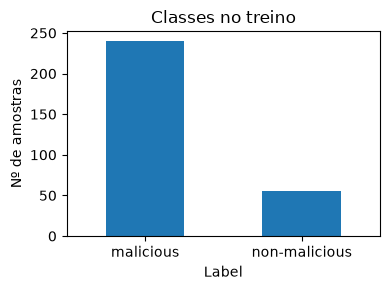

{1: 240, 0: 56}


In [24]:
fig, ax = plt.subplots(figsize=(4, 3))
y_train.map({0: 'non-malicious', 1: 'malicious'}).value_counts().plot(kind='bar', ax=ax)
ax.set_title('Classes no treino'); ax.set_ylabel('Nº de amostras'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
print(dict(Counter(y_train)))

### Comparar as formas de equilibrar
Testamos 5 formas e vemos qual dá melhor resultado na classe pequena.

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def rf(**kw):
    return RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1, **kw)

estrategias = {
    'Sem tratamento':       ImbPipeline([('clf', rf())]),
    'class_weight=balanced': ImbPipeline([('clf', rf(class_weight='balanced'))]),
    'RandomOverSampler':    ImbPipeline([('s', RandomOverSampler(random_state=RANDOM_STATE)), ('clf', rf())]),
    'RandomUnderSampler':   ImbPipeline([('s', RandomUnderSampler(random_state=RANDOM_STATE)), ('clf', rf())]),
    'SMOTE':                ImbPipeline([('s', SMOTE(random_state=RANDOM_STATE)), ('clf', rf())]),
}

# F1 da classe 0 (non-malicious = minoritária)
from sklearn.metrics import make_scorer
f1_min = make_scorer(f1_score, pos_label=0)

resultados = []
for nome, pipe in estrategias.items():
    scores = cross_val_score(pipe, X_train_sel, y_train, cv=skf, scoring=f1_min)
    resultados.append((nome, scores.mean(), scores.std()))

res = pd.DataFrame(resultados, columns=['Estratégia', 'F1 minoritária (média)', 'Desvio']).sort_values('F1 minoritária (média)', ascending=False)
res.round(3)

**Resultado:** as cinco formas dão resultados quase iguais. Isto quer dizer que os dados são fáceis de separar e que a diferença de tamanho das classes não está a atrapalhar. Por isso, a opção mais simples já chega.

### Aplicar a forma escolhida
Usamos o SMOTE como exemplo: cria amostras novas da classe pequena, parecidas com as que já existem. Só se aplica ao treino, nunca ao teste.

In [ ]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_bal, y_train_bal = smote.fit_resample(X_train_sel, y_train)

print('Antes :', dict(Counter(y_train)))
print('Depois:', dict(Counter(y_train_bal)))
print('Teste (inalterado):', dict(Counter(y_test)))

Antes : {1: 240, 0: 56}
Depois: {1: 240, 0: 240}
Teste (inalterado): {1: 61, 0: 14}


In [ ]:
# Verificação rápida (não é a avaliação final): treino balanceado -> teste original
# Um resultado perfeito reforça que o dataset é facilmente separável; com só 75 amostras de teste, não o tomes como garantia de desempenho real.
modelo = rf().fit(X_train_bal, y_train_bal)
print(classification_report(y_test, modelo.predict(X_test_sel), target_names=['non-malicious', 'malicious']))

               precision    recall  f1-score   support

non-malicious       1.00      1.00      1.00        14
    malicious       1.00      1.00      1.00        61

     accuracy                           1.00        75
    macro avg       1.00      1.00      1.00        75
 weighted avg       1.00      1.00      1.00        75



## 10. Guardar os dados preparados
Guardamos tudo em ficheiros na pasta `data_prepared`, para usar depois sem repetir os passos.

In [ ]:
out = Path('data_prepared'); out.mkdir(exist_ok=True)

def guardar(X_, y_, nome):
    pd.concat([X_, y_.rename('Label')], axis=1).to_csv(out / nome, index=False)

guardar(X_train_sel, y_train, 'train.csv')
guardar(X_test_sel, y_test, 'test.csv')
guardar(X_train_bal, y_train_bal, 'train_balanced_smote.csv')
guardar(X_train_std, y_train, 'train_standardized.csv')
guardar(X_test_std, y_test, 'test_standardized.csv')

print('Ficheiros guardados em', out.resolve())
for f in sorted(out.iterdir()):
    print('-', f.name)

Ficheiros guardados em D:\IAAC\grupo4-iaac\notebooks\1_data_preparation\data_prepared
- test.csv
- test_standardized.csv
- train.csv
- train_balanced_smote.csv
- train_standardized.csv


## Resumo

| Passo | O que fizemos |
|---|---|
| Linhas repetidas | Tirámos 2 |
| Colunas inúteis | Tirámos 28 |
| Valores em falta | Não há |
| Valores estranhos | Não apagámos nenhum |
| Divisão | 80% treino, 20% teste |
| Características | Ficámos só com as úteis, sem cópias |
| Escala | Só quando o modelo precisa |
| Classes de tamanhos diferentes | Testámos 5 formas, todas parecidas |